# Dingo tutorial, part 3: can we trust the network?

In part 2 the network gave the right answer for one signal. One signal proves little.
Here we test the network on **100 simulated signals** drawn from the whole prior, and look at two diagnostics.

* The **sample efficiency** of importance sampling, for each signal.
* The **probability-probability (P-P) plot**, a statistical test of the whole set of posteriors.

**Run time.** About 4 minutes the first time. The results are saved in the folder `results`, so that later runs
(for example to change a plot) take a few seconds.

In [1]:
import contextlib
import io
import os
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kstest

# The waveform library (LAL) redirects its messages when it runs inside a notebook.
# This makes waveform generation several times slower, so we switch the redirection off.
# The first two lines only hide the warning that LAL prints about this.
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal
lal.swig_redirect_standard_output_error(False)

from dingo.core.posterior_models.build_model import build_model_from_kwargs
from dingo.gw.inference.sampler import GWComposedSampler
from dingo.gw.injection import Injection
from dingo.gw.noise.asd_dataset import ASDDataset

import sys
sys.path.append("../figures")
from gwr_style import COLORS, TEXTWIDTH, save_figure, use_book_style

# Fix the random numbers, so that the notebook always gives the same result.
# Bilby draws the parameters from the prior, NumPy draws the noise,
# and PyTorch draws the samples from the network.
import bilby
import torch
bilby.core.utils.random.seed(7)
np.random.seed(7)
torch.manual_seed(7)

## Load the network and prepare the injections

This is the same as in part 2.

In [2]:
model = build_model_from_kwargs(filename="training/model_stage_0.pt", device="cpu", load_training_info=False)
detectors = model.metadata["train_settings"]["data"]["detectors"]

injection = Injection.from_posterior_model_metadata(model.metadata)
injection.asd = ASDDataset("training_data/asd_dataset.hdf5", ifos=detectors)

parameter_names = ["chirp_mass", "luminosity_distance"]

Putting posterior model to device cpu.
Setting spin_conversion_phase = None. Using phase parameter for conversion to cartesian spins.
Loading dataset from training_data/asd_dataset.hdf5.


## Analyse many signals

For each signal we:

1. draw the true parameters from the prior, and simulate the data;
2. draw 2000 samples from the network;
3. compute the importance weights;
4. store the sample efficiency;
5. store, for each parameter, the **fraction of the posterior that lies below the true value**.
   We compute this fraction twice: for the network alone (all samples count the same) and after importance sampling (using the weights).

The last quantity is what the P-P plot is made of. If the posterior is correct, the true value is
equally likely to fall anywhere in it. So over many signals these fractions should be spread uniformly between 0 and 1.

In [3]:
number_of_injections = 100
samples_per_injection = 2000

# The results are saved in this file. If the file already exists, the analysis is not repeated:
# the results are simply read from it. Delete the file to run the analysis again.
os.makedirs("results", exist_ok=True)
results_file = "results/validation_results.npz"

if not os.path.exists(results_file):
    efficiencies = []
    true_values = {name: [] for name in parameter_names}
    fraction_below_network = {name: [] for name in parameter_names}
    fraction_below_weighted = {name: [] for name in parameter_names}

    start_time = time.time()

    for i in range(number_of_injections):
        # Dingo prints several lines for each signal. We collect them in a text buffer
        # instead of showing them, to keep the notebook short.
        with contextlib.redirect_stdout(io.StringIO()):
            # 1. true parameters and simulated data
            true_parameters = injection.prior.sample()
            data = injection.injection(true_parameters)

            # 2. samples from the network
            sampler = GWComposedSampler.from_model(model, data)
            sampler.run_sampler(num_samples=samples_per_injection, batch_size=samples_per_injection)
            result = sampler.to_result()

            # 3. importance sampling
            result.importance_sample()
        weights = result.samples["weights"].to_numpy()

        # 4. sample efficiency
        efficiencies.append(result.sample_efficiency)

        # 5. fraction of the posterior below the true value
        for name in parameter_names:
            below = result.samples[name].to_numpy() < true_parameters[name]
            fraction_below_network[name].append(np.mean(below))
            fraction_below_weighted[name].append(np.sum(weights[below]) / np.sum(weights))
            true_values[name].append(true_parameters[name])

        # show the progress every 25 signals
        if (i + 1) % 25 == 0:
            print(f"{i + 1} signals analysed")

    elapsed = time.time() - start_time
    print(f"Done: {elapsed / 60:.1f} minutes in total, {elapsed / number_of_injections:.1f} seconds per signal.")

    # Save everything that the plots below need
    np.savez(
        results_file,
        efficiencies=efficiencies,
        **{f"true_{name}": true_values[name] for name in parameter_names},
        **{f"network_{name}": fraction_below_network[name] for name in parameter_names},
        **{f"weighted_{name}": fraction_below_weighted[name] for name in parameter_names},
    )
else:
    print(f"Results read from {results_file}.")

# Read the results from the file
saved = np.load(results_file)
efficiencies = saved["efficiencies"]
true_values = {name: saved[f"true_{name}"] for name in parameter_names}
fraction_below_network = {name: saved[f"network_{name}"] for name in parameter_names}
fraction_below_weighted = {name: saved[f"weighted_{name}"] for name in parameter_names}

Results read from results/validation_results.npz.


## Sample efficiency

In [4]:
print(f"Median sample efficiency: {100 * np.median(efficiencies):.0f}%")
print(f"Lowest sample efficiency: {100 * efficiencies.min():.1f}%")
print(f"Signals with efficiency above 10%: {100 * np.mean(efficiencies > 0.1):.0f}%")

Median sample efficiency: 80%
Lowest sample efficiency: 27.1%
Signals with efficiency above 10%: 100%


## The P-P plot

Dingo can make this plot automatically: the command `dingo_pipe_pp_test` builds it from a folder of result files.
Here we build it by hand, to show how it works.

Sort the 100 fractions of one parameter and plot them against 1/100, 2/100, ..., 1.
If they are uniformly distributed, the curve follows the diagonal.

With a finite number of signals the curve fluctuates around the diagonal.
The grey band shows the size of the fluctuations expected by chance (three standard deviations).

We also want a number that tells us whether the curve is compatible with the diagonal.
This is the job of the **Kolmogorov-Smirnov (KS) test**. It measures the largest distance between the curve and the diagonal,
and converts it into a *p-value*: the probability that a deviation at least this large arises by chance.
A very small p-value (say below 0.01) signals a problem. We write the p-value of each parameter in the legend.

Network alone             chirp_mass           KS p-value = 0.26
Network alone             luminosity_distance  KS p-value = 0.94
With importance sampling  chirp_mass           KS p-value = 0.31
With importance sampling  luminosity_distance  KS p-value = 0.80


Figure saved to output/fig_validation.pdf


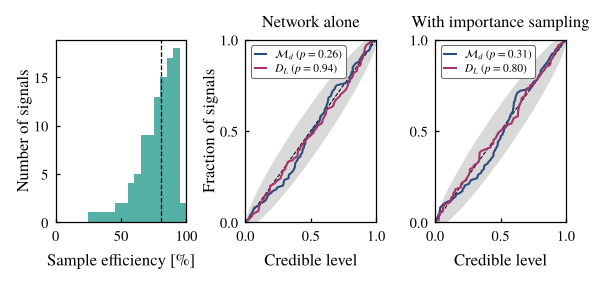

In [5]:
def pp_curve(fractions):
    """Sorted fractions (x) against the cumulative fraction of signals (y)."""
    x = np.sort(fractions)
    y = np.arange(1, len(x) + 1) / len(x)
    return x, y


labels = {"chirp_mass": r"$\mathcal{M}_d$", "luminosity_distance": r"$D_L$"}
line_colors = {"chirp_mass": COLORS["blue"], "luminosity_distance": COLORS["magenta"]}

use_book_style()  # make sure the style of the book is active
fig, axes = plt.subplots(1, 3, figsize=(TEXTWIDTH, 0.36 * TEXTWIDTH), gridspec_kw={"wspace": 0.45})

# Expected fluctuations around the diagonal
p = np.linspace(0, 1, 200)
band = 3 * np.sqrt(p * (1 - p) / number_of_injections)

# First panel: histogram of the sample efficiencies
ax = axes[0]
ax.hist(100 * efficiencies, bins=np.linspace(0, 100, 21), color=COLORS["teal"], alpha=0.8)
ax.axvline(100 * np.median(efficiencies), color="k", lw=0.6, ls="--")
ax.set_xlim(0, 100)
ax.set_xlabel("Sample efficiency [%]")
ax.set_ylabel("Number of signals", labelpad=1)

# Second and third panels: P-P plots
titles = ["Network alone", "With importance sampling"]
for ax, fractions, title in zip(axes[1:], [fraction_below_network, fraction_below_weighted], titles):
    ax.fill_between(p, p - band, p + band, color=COLORS["lightgrey"], lw=0)
    ax.plot([0, 1], [0, 1], color="k", lw=0.5, ls="--")
    for name in parameter_names:
        # KS test: are the fractions uniformly distributed between 0 and 1?
        p_value = kstest(fractions[name], "uniform").pvalue
        print(f"{title:25s} {name:20s} KS p-value = {p_value:.2f}")
        ax.plot(*pp_curve(fractions[name]), color=line_colors[name], lw=1.0,
                label=f"{labels[name]} ($p={p_value:.2f}$)")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xticks([0, 0.5, 1])
    ax.set_yticks([0, 0.5, 1])
    ax.set_xlabel("Credible level")
    ax.set_title(title)
    ax.legend(loc="upper left", fontsize=5.5, handlelength=1.0, borderpad=0.3, labelspacing=0.2)
axes[1].set_ylabel("Fraction of signals", labelpad=1)

for ax in axes:
    ax.tick_params(length=2)

save_figure(fig, "fig_validation.pdf")
plt.show()

**How to read the P-P plot.**

* A curve on the diagonal: the posteriors are statistically correct.
* An S-shaped curve: the posteriors are systematically too narrow or too broad.
* A curve entirely above or below the diagonal: the posteriors are shifted (biased).

The left panel shows the sample efficiencies. The dashed line is the median.

## Where does the network struggle?

The sample efficiency is available for every signal. We can look for the regions of parameter space where it is low.

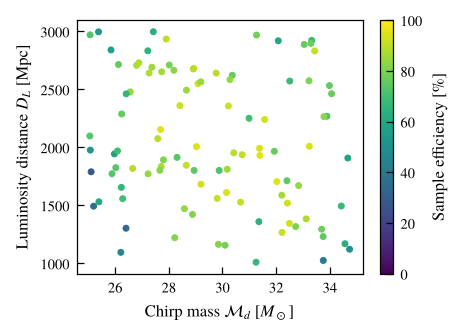

In [6]:
use_book_style()  # make sure the style of the book is active
fig, ax = plt.subplots(figsize=(0.7 * TEXTWIDTH, 0.5 * TEXTWIDTH))
points = ax.scatter(true_values["chirp_mass"], true_values["luminosity_distance"], c=100 * efficiencies,
                    s=8, cmap="viridis", vmin=0, vmax=100)
fig.colorbar(points, label="Sample efficiency [%]")
ax.set_xlabel(r"Chirp mass $\mathcal{M}_d$ [$M_\odot$]")
ax.set_ylabel(r"Luminosity distance $D_L$ [Mpc]")
plt.show()

The efficiency is high almost everywhere. The lowest values are found near the edges of the prior, in particular at the lowest chirp masses.
There the posterior is cut by the edge of the prior, a shape that is harder for the network to learn.